In [1]:
# =============================================================================
# CROSS-LINGUAL TRANSFER — SINGLE SHARED HEAD VARIANT
# =============================================================================
# Architecture change vs original notebook:
#   OLD: sent_head (CLS→4)  +  intent_head (CLS→256→6)  — two separate heads
#   NEW: shared_trunk (CLS→512→256) feeds two thin output projections
#        sent_proj  (256→4)
#        intent_proj(256→6)
#   The trunk is shared: both tasks build on the same intermediate
#   representation, so gradients from both losses mutually reinforce it.
#
# Cross-lingual transfer pipeline (unchanged logic, CPU-safe):
#   Stage 1  → English fine-tune  (GoEmotions + CLINC150)
#   Stage 2a → Sinhala heads-only (encoder frozen)
#   Stage 2b → Sinhala full tune  (encoder unfrozen, LR=2e-6)
# =============================================================================

In [2]:
# ── Cell 2: Imports & config ──────────────────────────────────────────────────
import os
import re, random, unicodedata
import numpy as np
import pandas as pd
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModel,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score

# ── Paths ─────────────────────────────────────────────────────────────────────
SINHALA_CSV   = "/kaggle/input/datasets/thiwankachanditha/sold-data-sentiment-intent/sinhala_silver_labels.csv"
OUTPUT_DIR    = "/kaggle/working/outputs"
CKPT_DIR      = "/kaggle/working/checkpoints"
MODEL_DIR     = "/kaggle/working/saved_model"
for d in [OUTPUT_DIR, CKPT_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

TEXT_COL      = "text"
SENTIMENT_COL = "sentiment_label"
INTENT_COL    = "intent_label"

SENTIMENT_CLASSES = ["positive", "negative", "neutral", "conflict"]
INTENT_CLASSES    = ["suggestion", "complaint", "inquiry", "feedback", "greeting", "other"]
NUM_SENTIMENTS    = len(SENTIMENT_CLASSES)
NUM_INTENTS       = len(INTENT_CLASSES)

BACKBONE       = "xlm-roberta-base"
MAX_LEN        = 128
BATCH_SIZE     = 32
DROPOUT        = 0.3
GRAD_CLIP      = 1.0
WEIGHT_DECAY   = 0.01
WARMUP_RATIO   = 0.1
SEED           = 42
SENT_SMOOTH    = 0.10
INTENT_SMOOTH  = 0.15
ALPHA          = 0.5

# Stage-specific learning rates
LR_STAGE1      = 2e-5
LR_STAGE2A     = 2e-5
LR_STAGE2B     = 2e-6   # 10× lower — prevents catastrophic forgetting

EPOCHS_STAGE1  = 5
EPOCHS_STAGE2A = 3
EPOCHS_STAGE2B = 10
PATIENCE       = 3

print("Sentiment classes:", SENTIMENT_CLASSES)
print("Intent classes   :", INTENT_CLASSES)

Sentiment classes: ['positive', 'negative', 'neutral', 'conflict']
Intent classes   : ['suggestion', 'complaint', 'inquiry', 'feedback', 'greeting', 'other']


In [3]:
import torch

# ── Cell 3: Utilities ─────────────────────────────────────────────────────────
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", "", text)
    return re.sub(r"\s+", " ", text).strip()

set_seed()
print("Seed set. Utilities ready.")

Seed set. Utilities ready.


In [4]:
# ── Cell 4: Model — single shared trunk ──────────────────────────────────────
# ─────────────────────────────────────────────────────────────────────────────
#  XLM-RoBERTa encoder
#       │
#      [CLS]  (768-dim)
#       │
#  shared_trunk:  Linear(768→512) → GELU → Dropout → Linear(512→256) → GELU
#       │
#   ┌───┴───────────────┐
#  sent_proj          intent_proj
#  Linear(256→4)      Linear(256→6)
#
# Why one trunk instead of two independent heads?
#   - Both tasks share the 256-dim intermediate representation.
#   - Gradients from both cross-entropy losses flow back through the trunk
#     jointly, forcing it to learn features useful for *both* tasks.
#   - The two thin projections stay task-specific so each output space
#     is still independent.
#   - With only 1000 Sinhala samples this parameter sharing acts as an
#     implicit regulariser — the trunk has fewer "wasted" parameters
#     compared to two separate deeper heads.
# ─────────────────────────────────────────────────────────────────────────────

from transformers import AutoModel

class JointModel(nn.Module):
    def __init__(self, backbone=BACKBONE,
                 ns=NUM_SENTIMENTS, ni=NUM_INTENTS, do=DROPOUT):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(backbone)
        h = self.encoder.config.hidden_size          # 768 for xlm-roberta-base

        # ── Single shared trunk ───────────────────────────────────────────────
        self.shared_trunk = nn.Sequential(
            nn.Dropout(do),
            nn.Linear(h, 512),
            nn.GELU(),
            nn.Dropout(do),
            nn.Linear(512, 256),
            nn.GELU(),
        )

        # ── Task-specific output projections (thin — just one linear each) ───
        self.sent_proj   = nn.Linear(256, ns)   # 256 → 4  sentiment classes
        self.intent_proj = nn.Linear(256, ni)   # 256 → 6  intent classes

    def forward(self, input_ids, attention_mask):
        # 1. Encode text → [CLS] representation
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]         # [B, 768]

        # 2. Shared trunk — both tasks use this representation
        shared = self.shared_trunk(cls)              # [B, 256]

        # 3. Task-specific projections
        sent_logits   = self.sent_proj(shared)       # [B, 4]
        intent_logits = self.intent_proj(shared)     # [B, 6]

        return sent_logits, intent_logits

    def get_param_groups(self, lr, wd):
        """
        Three LR tiers:
          encoder params (no decay)    → lr
          encoder params (with decay)  → lr
          trunk + projection heads     → lr * 10
        """
        nd     = ["bias", "LayerNorm.weight"]
        enc    = list(self.encoder.named_parameters())
        # shared trunk + both projections treated as one group
        heads  = (list(self.shared_trunk.named_parameters()) +
                  list(self.sent_proj.named_parameters())   +
                  list(self.intent_proj.named_parameters()))
        return [
            {"params": [p for n,p in enc   if not any(d in n for d in nd)],
             "lr": lr,      "weight_decay": wd},
            {"params": [p for n,p in enc   if     any(d in n for d in nd)],
             "lr": lr,      "weight_decay": 0.0},
            {"params": [p for n,p in heads if not any(d in n for d in nd)],
             "lr": lr * 10, "weight_decay": wd},
            {"params": [p for n,p in heads if     any(d in n for d in nd)],
             "lr": lr * 10, "weight_decay": 0.0},
        ]

    def freeze_encoder(self):
        for p in self.encoder.parameters():
            p.requires_grad = False
        print("Encoder frozen — only shared trunk + projections will train.")

    def unfreeze_encoder(self):
        for p in self.encoder.parameters():
            p.requires_grad = True
        print("Encoder unfrozen — full model will train.")

In [5]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")

from huggingface_hub import login
login(token=secret_value_0)

In [6]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(DEVICE)

cuda


In [7]:
# Smoke-test the architecture
print("Loading XLM-R backbone (~1.1 GB on first run) …")
model = JointModel().to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f"Model on {DEVICE}   Total params: {total_params:,}")

dummy_ids  = torch.zeros(2, MAX_LEN, dtype=torch.long).to(DEVICE)
dummy_mask = torch.ones(2,  MAX_LEN, dtype=torch.long).to(DEVICE)
s_out, i_out = model(dummy_ids, dummy_mask)
print(f"Forward pass OK  →  sentiment {s_out.shape}   intent {i_out.shape}")

Loading XLM-R backbone (~1.1 GB on first run) …


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model on cuda   Total params: 278,571,274
Forward pass OK  →  sentiment torch.Size([2, 4])   intent torch.Size([2, 6])


In [8]:
# ── Cell 5: Dataset & DataLoaders (identical to your original) ───────────────
class SinhalaJointDataset(Dataset):
    def __init__(self, texts, sent_lbl, intent_lbl, tokenizer, max_len=MAX_LEN):
        self.texts      = texts
        self.sent_lbl   = sent_lbl
        self.intent_lbl = intent_lbl
        self.tok        = tokenizer
        self.max_len    = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tok(
            str(self.texts[idx]),
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        return {
            "input_ids":       enc["input_ids"].squeeze(0),
            "attention_mask":  enc["attention_mask"].squeeze(0),
            "sentiment_label": torch.tensor(self.sent_lbl[idx],   dtype=torch.long),
            "intent_label":    torch.tensor(self.intent_lbl[idx], dtype=torch.long),
        }

def make_loader(df, tok, shuffle=False):
    ds = SinhalaJointDataset(
        df[TEXT_COL].tolist(),
        df[SENTIMENT_COL].tolist(),
        df[INTENT_COL].tolist(),
        tok,
    )
    return DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=2, pin_memory=True,
    )

print("Loading tokenizer …")
tokenizer = AutoTokenizer.from_pretrained(BACKBONE)
print(f"Vocab size: {tokenizer.vocab_size}")

Loading tokenizer …


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Vocab size: 250002


In [9]:
# ── Cell 6: Loss function (identical to your original) ───────────────────────
sc = nn.CrossEntropyLoss(label_smoothing=SENT_SMOOTH)
ic = nn.CrossEntropyLoss(label_smoothing=INTENT_SMOOTH)

def jloss(sl, il, slbl, ilbl):
    ls = sc(sl, slbl)
    li = ic(il, ilbl)
    return ALPHA * ls + (1 - ALPHA) * li, ls, li

In [10]:
# ── Cell 7: Generic train / eval loops ───────────────────────────────────────
def train_one_epoch(model, loader, optimizer, scheduler):
    model.train()
    tot = tsl = til = 0.0
    for b in loader:
        ids   = b["input_ids"].to(DEVICE)
        mask  = b["attention_mask"].to(DEVICE)
        s_lbl = b["sentiment_label"].to(DEVICE)
        i_lbl = b["intent_label"].to(DEVICE)

        s_log, i_log     = model(ids, mask)
        loss, ls, li     = jloss(s_log, i_log, s_lbl, i_lbl)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()

        tot += loss.item(); tsl += ls.item(); til += li.item()

    n = len(loader)
    return tot / n, tsl / n, til / n


def evaluate(model, loader):
    model.eval()
    tot = cs = ci = jc = total = 0
    all_sp, all_ip, all_sl, all_il = [], [], [], []

    with torch.no_grad():
        for b in loader:
            ids   = b["input_ids"].to(DEVICE)
            mask  = b["attention_mask"].to(DEVICE)
            s_lbl = b["sentiment_label"].to(DEVICE)
            i_lbl = b["intent_label"].to(DEVICE)

            s_log, i_log = model(ids, mask)
            loss, _, _   = jloss(s_log, i_log, s_lbl, i_lbl)
            tot += loss.item()

            sp = s_log.argmax(1); ip = i_log.argmax(1)
            cs    += (sp == s_lbl).sum().item()
            ci    += (ip == i_lbl).sum().item()
            jc    += ((sp == s_lbl) & (ip == i_lbl)).sum().item()
            total += s_lbl.size(0)

            all_sp.extend(sp.cpu().tolist())
            all_ip.extend(ip.cpu().tolist())
            all_sl.extend(s_lbl.cpu().tolist())
            all_il.extend(i_lbl.cpu().tolist())

    f1_s = f1_score(all_sl, all_sp, average="macro", zero_division=0)
    f1_i = f1_score(all_il, all_ip, average="macro", zero_division=0)
    jcs  = (2 * f1_s * f1_i / (f1_s + f1_i)) if (f1_s + f1_i) > 0 else 0.0

    return {
        "loss":  tot / len(loader),
        "s_acc": cs / total,
        "i_acc": ci / total,
        "j_acc": jc / total,
        "f1_s":  f1_s,
        "f1_i":  f1_i,
        "jcs":   jcs,
    }


def run_training_loop(model, train_loader, val_loader,
                      lr, epochs, ckpt_path,
                      patience=PATIENCE,
                      use_jcs=True,
                      stage_label=""):
    total_steps = len(train_loader) * epochs
    optimizer   = torch.optim.AdamW(model.get_param_groups(lr, WEIGHT_DECAY))
    scheduler   = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * WARMUP_RATIO),
        num_training_steps=total_steps,
    )

    best  = -float("inf") if use_jcs else float("inf")
    pat   = 0
    history = []

    print(f"\n{'='*58}")
    print(f"  {stage_label}")
    print(f"{'='*58}")

    for epoch in range(1, epochs + 1):
        tl, tsl, til = train_one_epoch(model, train_loader, optimizer, scheduler)
        vm = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": tl, **vm})

        print(f"\nEpoch {epoch}/{epochs}")
        print(f"  Train  loss={tl:.4f}  sent={tsl:.4f}  intent={til:.4f}")
        print(f"  Val    loss={vm['loss']:.4f}  s_acc={vm['s_acc']:.4f}"
              f"  i_acc={vm['i_acc']:.4f}  j_acc={vm['j_acc']:.4f}"
              f"  JCS={vm['jcs']:.4f}")

        score    = vm["jcs"] if use_jcs else -vm["loss"]
        improved = score > best

        if improved:
            best = score; pat = 0
            torch.save({"epoch": epoch, "model_state": model.state_dict(),
                        "val_loss": vm["loss"], "jcs": vm["jcs"]}, ckpt_path)
            print(f"  [SAVED] → {ckpt_path}")
        else:
            pat += 1
            print(f"  No improvement ({pat}/{patience})")
            if pat >= patience:
                print(f"  Early stopping at epoch {epoch}")
                break

    return history

In [11]:
# ── Cell 8: Sinhala label maps & loader (identical to your original) ─────────
SENTIMENT_MAP = {
    "positive": 0, "Positive": 0, "POSITIVE": 0,
    "negative": 1, "Negative": 1, "NEGATIVE": 1,
    "neutral":  2, "Neutral":  2, "NEUTRAL":  2,
    "conflict": 3, "Conflict": 3, "CONFLICT": 3,
}
INTENT_MAP = {
    "inquiry":     0, "Inquiry":     0, "INQUIRY":     0,
    "complaint": 1, "Complaint": 1, "COMPLAINT": 1,
    "suggestion":   2, "Suggestion":   2, "SUGGESTION":   2,
    "feedback":  3, "Feedback":  3, "FEEDBACK":  3,
    "greeting":  4, "Greeting":  4, "GREETING":  4,
    "other":     5, "Other":     5, "OTHER":     5,
}

def load_sinhala():
    df = pd.read_csv(SINHALA_CSV)
    df.rename(columns={
        "Sentence": "text",  "sentence": "text",  "Text": "text",
        "intent":   INTENT_COL,   "Intent":   INTENT_COL,
        "sentiment":SENTIMENT_COL,"Sentiment":SENTIMENT_COL,
    }, inplace=True)

    print(f"Columns          : {list(df.columns)}")
    print(f"Sentiment unique : {sorted(df[SENTIMENT_COL].astype(str).unique())}")
    print(f"Intent unique    : {sorted(df[INTENT_COL].astype(str).unique())}")

    df[TEXT_COL] = df[TEXT_COL].apply(clean_text)

    if not pd.api.types.is_integer_dtype(df[SENTIMENT_COL]):
        unk = set(df[SENTIMENT_COL].unique()) - set(SENTIMENT_MAP)
        if unk: print("WARNING unknown sentiment:", unk)
        df[SENTIMENT_COL] = df[SENTIMENT_COL].map(SENTIMENT_MAP)

    if not pd.api.types.is_integer_dtype(df[INTENT_COL]):
        unk = set(df[INTENT_COL].unique()) - set(INTENT_MAP)
        if unk: print("WARNING unknown intent:", unk)
        df[INTENT_COL] = df[INTENT_COL].map(INTENT_MAP)

    before = len(df)
    df = df.dropna(subset=[SENTIMENT_COL, INTENT_COL])
    if before - len(df):
        print(f"Dropped {before - len(df)} unmapped rows")

    df[SENTIMENT_COL] = df[SENTIMENT_COL].astype(int)
    df[INTENT_COL]    = df[INTENT_COL].astype(int)
    df = df[df[TEXT_COL].str.len() > 0].reset_index(drop=True)
    print(f"Rows after clean : {len(df)}")
    return df

In [12]:
# ── Cell 9: English dataset loader ───────────────────────────────────────────
# GoEmotions 28 emotions → your 4 sentiment classes
GOEMO_TO_SENTIMENT = {
    "admiration":0,"amusement":0,"approval":0,"caring":0,"desire":0,
    "excitement":0,"gratitude":0,"joy":0,"love":0,"optimism":0,
    "pride":0,"relief":0,"surprise":0,
    "anger":1,"annoyance":1,"disappointment":1,"disapproval":1,
    "disgust":1,"embarrassment":1,"fear":1,"grief":1,
    "nervousness":1,"remorse":1,"sadness":1,
    "neutral":2,"realization":2,"curiosity":2,
    "confusion":3,
}

# CLINC150 → your 6 intent classes (unmapped → "other" = 5)
CLINC_TO_INTENT = {
    "make_call":0,"todo_list":0,"todo_list_update":0,"calendar":0,
    "calendar_update":0,"set_alarm":0,"reminder":0,"reminder_update":0,
    "shopping_list":0,"shopping_list_update":0,
    "cancel":1,"cancel_reservation":1,"report_lost_card":1,
    "damaged_card":1,"freeze_account":1,"dispute_charge":1,"card_declined":1,
    "balance":2,"transactions":2,"bill_balance":2,"interest_rate":2,
    "account_blocked":2,"min_payment":2,"pay_bill":2,"bill_due":2,
    "credit_score":2,"credit_limit":2,"credit_limit_change":2,
    "exchange_rate":2,"transfer":2,"direct_deposit":2,
    "international_fees":2,"routing":2,"what_is_your_name":2,
    "who_made_you":2,"time":2,"date":2,"weather":2,"flip_coin":2,
    "roll_dice":2,"definition":2,"math":2,"distance":2,"convert":2,
    "measurement_conversion":2,"calories":2,"nutrition_info":2,
    "flight_status":2,"travel_notification":2,"restaurant_reservation":2,
    "restaurant_reviews":2,"restaurant_suggestion":2,"directions":2,
    "traffic":2,"gas":2,"gas_type":2,"current_location":2,"timezone":2,
    "insurance":2,"insurance_change":2,"find_phone":2,"lost_luggage":2,
    "user_name":3,"change_user_name":3,"change_language":3,
    "change_accent":3,"change_speed":3,"change_volume":3,
    "reset_settings":3,"report_fraud":3,
    "greeting":4,"goodbye":4,"tell_joke":4,"are_you_a_bot":4,
    "yes":4,"no":4,"thank_you":4,"repeat":4,"how_busy":4,
}

def load_english(max_rows=16000):
    from datasets import load_dataset

    print("\n── Loading GoEmotions ──")
    goe = load_dataset("go_emotions", "simplified", split="train")
    label_names = goe.features["labels"].feature.names
    goe_rows = []
    for ex in goe:
        text = clean_text(ex["text"])
        if not text or len(ex["labels"]) != 1:
            continue
        s = GOEMO_TO_SENTIMENT.get(label_names[ex["labels"][0]])
        if s is None:
            continue
        goe_rows.append({TEXT_COL: text, SENTIMENT_COL: s, INTENT_COL: 5})
    df_goe = pd.DataFrame(goe_rows)
    print(f"  rows: {len(df_goe)}")

    print("── Loading CLINC150 ──")
    clinc = load_dataset("clinc_oos", "plus", split="train")
    intent_names = clinc.features["intent"].names
    clinc_rows = []
    for ex in clinc:
        text = clean_text(ex["text"])
        if not text:
            continue
        i = CLINC_TO_INTENT.get(intent_names[ex["intent"]], 5)
        clinc_rows.append({TEXT_COL: text, SENTIMENT_COL: 2, INTENT_COL: i})
    df_clinc = pd.DataFrame(clinc_rows)
    print(f"  rows: {len(df_clinc)}")

    df = pd.concat([df_goe, df_clinc], ignore_index=True)
    df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
    if len(df) > max_rows:
        df = df.iloc[:max_rows]

    print(f"\nTotal English rows : {len(df)}")
    print("Sentiment dist:")
    for idx, cnt in df[SENTIMENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {SENTIMENT_CLASSES[idx]:<12} {cnt:>5}")
    print("Intent dist:")
    for idx, cnt in df[INTENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {INTENT_CLASSES[idx]:<12} {cnt:>5}")
    return df

In [13]:
# ── Cell 10: STAGE 1 — English fine-tuning ───────────────────────────────────
df_en = load_english(max_rows=16000)

df_en_train, df_en_val = train_test_split(
    df_en, test_size=0.10,
    stratify=df_en[SENTIMENT_COL], random_state=SEED,
)
print(f"English split — Train: {len(df_en_train)}  Val: {len(df_en_val)}")

en_train_loader = make_loader(df_en_train, tokenizer, shuffle=True)
en_val_loader   = make_loader(df_en_val,   tokenizer)

# Fresh model for Stage 1
model = JointModel().to(DEVICE)

stage1_ckpt = os.path.join(CKPT_DIR, "stage1_english_best.pt")

history_s1 = run_training_loop(
    model,
    train_loader=en_train_loader,
    val_loader=en_val_loader,
    lr=LR_STAGE1,
    epochs=EPOCHS_STAGE1,
    ckpt_path=stage1_ckpt,
    use_jcs=False,          # val_loss for English (mapped labels, JCS less meaningful)
    stage_label="Stage 1 — English fine-tuning  (shared trunk warm-up)",
)

ckpt = torch.load(stage1_ckpt, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
print(f"\nLoaded Stage 1 best  (epoch {ckpt['epoch']}  val_loss={ckpt['val_loss']:.4f})")


── Loading GoEmotions ──


README.md: 0.00B [00:00, ?B/s]

simplified/train-00000-of-00001.parquet:   0%|          | 0.00/2.77M [00:00<?, ?B/s]

simplified/validation-00000-of-00001.par(…):   0%|          | 0.00/350k [00:00<?, ?B/s]

simplified/test-00000-of-00001.parquet:   0%|          | 0.00/347k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  Stage 1 — English fine-tuning  (shared trunk warm-up)

Epoch 1/5
  Train  loss=0.9870  sent=0.9836  intent=0.9904
  Val    loss=0.7855  s_acc=0.7875  i_acc=0.8831  j_acc=0.6706  JCS=0.3080
  No improvement (1/3)

Epoch 2/5
  Train  loss=0.7651  sent=0.7417  intent=0.7884
  Val    loss=0.7308  s_acc=0.7781  i_acc=0.9281  j_acc=0.7081  JCS=0.4918
  No improvement (2/3)

Epoch 3/5
  Train  loss=0.6853  sent=0.6688  intent=0.7018
  Val    loss=0.7028  s_acc=0.7913  i_acc=0.9600  j_acc=0.7538  JCS=0.6405
  No improvement (3/3)
  Early stopping at epoch 3


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/checkpoints/stage1_english_best.pt'

In [14]:
# ── Cell 11: Split Sinhala data ───────────────────────────────────────────────
df_si = load_sinhala()

df_si_train, df_si_temp = train_test_split(
    df_si, test_size=0.30,
    stratify=df_si[SENTIMENT_COL], random_state=SEED,
)
df_si_val, df_si_test = train_test_split(
    df_si_temp, test_size=0.50,
    stratify=df_si_temp[SENTIMENT_COL], random_state=SEED,
)

df_si_train.to_csv("/kaggle/working/train.csv", index=False)
df_si_val.to_csv(  "/kaggle/working/val.csv",   index=False)
df_si_test.to_csv( "/kaggle/working/test.csv",  index=False)

print(f"\nSinhala split — Train: {len(df_si_train)}  Val: {len(df_si_val)}  Test: {len(df_si_test)}")

for name, df in [("TRAIN", df_si_train), ("VAL", df_si_val), ("TEST", df_si_test)]:
    print(f"\n-- {name} Sentiment --")
    for idx, cnt in df[SENTIMENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {SENTIMENT_CLASSES[idx]:<12} {cnt:>5} ({cnt/len(df)*100:.1f}%)")
    print(f"-- {name} Intent --")
    for idx, cnt in df[INTENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {INTENT_CLASSES[idx]:<12} {cnt:>5} ({cnt/len(df)*100:.1f}%)")

si_train_loader = make_loader(df_si_train, tokenizer, shuffle=True)
si_val_loader   = make_loader(df_si_val,   tokenizer)
si_test_loader  = make_loader(df_si_test,  tokenizer)

Columns          : ['text', 'sentiment_label', 'intent_label', 'combined_label', 'nli_conf', 'conf_tier', 'nli_rule_agree', 'sample_weight']
Sentiment unique : ['Conflict', 'Negative', 'Neutral', 'Positive']
Intent unique    : ['complaint', 'feedback', 'greeting', 'inquiry', 'other', 'suggestion']
Rows after clean : 5881

Sinhala split — Train: 4116  Val: 882  Test: 883

-- TRAIN Sentiment --
  [0] positive       278 (6.8%)
  [1] negative      1074 (26.1%)
  [2] neutral       2721 (66.1%)
  [3] conflict        43 (1.0%)
-- TRAIN Intent --
  [0] suggestion    2246 (54.6%)
  [1] complaint      382 (9.3%)
  [2] inquiry        314 (7.6%)
  [3] feedback       562 (13.7%)
  [4] greeting       401 (9.7%)
  [5] other          211 (5.1%)

-- VAL Sentiment --
  [0] positive        59 (6.7%)
  [1] negative       230 (26.1%)
  [2] neutral        583 (66.1%)
  [3] conflict        10 (1.1%)
-- VAL Intent --
  [0] suggestion     475 (53.9%)
  [1] complaint       67 (7.6%)
  [2] inquiry         68 (7.

In [15]:
# ── Cell 12: STAGE 2a — Sinhala heads-only warm-up ───────────────────────────
# Encoder frozen. Only shared_trunk + sent_proj + intent_proj update.
# The shared trunk adapts its 256-dim representation to Sinhala without
# disturbing the cross-lingual alignment built during Stage 1.

model.freeze_encoder()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,}  ({100*trainable/total:.1f}%)")

stage2a_ckpt = os.path.join(CKPT_DIR, "stage2a_headsonly_best.pt")

history_s2a = run_training_loop(
    model,
    train_loader=si_train_loader,
    val_loader=si_val_loader,
    lr=LR_STAGE2A,
    epochs=EPOCHS_STAGE2A,
    ckpt_path=stage2a_ckpt,
    use_jcs=True,
    stage_label="Stage 2a — Sinhala heads-only  (encoder frozen)",
)

ckpt = torch.load(stage2a_ckpt, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
print(f"\nLoaded Stage 2a best  (epoch {ckpt['epoch']}  JCS={ckpt['jcs']:.4f})")

Encoder frozen — only shared trunk + projections will train.
Trainable: 527,626 / 278,571,274  (0.2%)

  Stage 2a — Sinhala heads-only  (encoder frozen)

Epoch 1/3
  Train  loss=1.2804  sent=0.9367  intent=1.6241
  Val    loss=1.0726  s_acc=0.7018  i_acc=0.6270  j_acc=0.4637  JCS=0.3306
  [SAVED] → /kaggle/working/checkpoints/stage2a_headsonly_best.pt

Epoch 2/3
  Train  loss=1.0678  sent=0.8620  intent=1.2736
  Val    loss=1.0646  s_acc=0.6950  i_acc=0.6247  j_acc=0.4399  JCS=0.3571
  [SAVED] → /kaggle/working/checkpoints/stage2a_headsonly_best.pt

Epoch 3/3
  Train  loss=1.0611  sent=0.8600  intent=1.2621
  Val    loss=1.0518  s_acc=0.6916  i_acc=0.6327  j_acc=0.4512  JCS=0.3520
  No improvement (1/3)

Loaded Stage 2a best  (epoch 2  JCS=0.3571)


In [16]:
# ── Cell 13: STAGE 2b — Sinhala full fine-tuning ─────────────────────────────
# Unfreeze everything. LR is 10× lower than Stage 1 to prevent forgetting.
# JCS used for checkpoint selection — saves best joint-task model directly.

model.unfreeze_encoder()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable: {trainable:,} / {total:,}  (fully unfrozen)")

stage2b_ckpt = os.path.join(CKPT_DIR, "stage2b_fulltune_best.pt")

history_s2b = run_training_loop(
    model,
    train_loader=si_train_loader,
    val_loader=si_val_loader,
    lr=LR_STAGE2B,
    epochs=EPOCHS_STAGE2B,
    ckpt_path=stage2b_ckpt,
    use_jcs=True,
    stage_label="Stage 2b — Sinhala full fine-tune  (LR=2e-6, all unfrozen)",
)

ckpt = torch.load(stage2b_ckpt, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
print(f"\nLoaded Stage 2b best  (epoch {ckpt['epoch']}  JCS={ckpt['jcs']:.4f})")

Encoder unfrozen — full model will train.
Trainable: 278,571,274 / 278,571,274  (fully unfrozen)

  Stage 2b — Sinhala full fine-tune  (LR=2e-6, all unfrozen)

Epoch 1/10
  Train  loss=1.0565  sent=0.8574  intent=1.2557
  Val    loss=1.0400  s_acc=0.6893  i_acc=0.6372  j_acc=0.4478  JCS=0.3587
  [SAVED] → /kaggle/working/checkpoints/stage2b_fulltune_best.pt

Epoch 2/10
  Train  loss=1.0263  sent=0.8376  intent=1.2149
  Val    loss=1.0142  s_acc=0.7166  i_acc=0.6667  j_acc=0.4989  JCS=0.4190
  [SAVED] → /kaggle/working/checkpoints/stage2b_fulltune_best.pt

Epoch 3/10
  Train  loss=0.9935  sent=0.8151  intent=1.1719
  Val    loss=0.9944  s_acc=0.7268  i_acc=0.6814  j_acc=0.5170  JCS=0.4447
  [SAVED] → /kaggle/working/checkpoints/stage2b_fulltune_best.pt

Epoch 4/10
  Train  loss=0.9693  sent=0.7977  intent=1.1408
  Val    loss=0.9838  s_acc=0.7279  i_acc=0.6973  j_acc=0.5306  JCS=0.4670
  [SAVED] → /kaggle/working/checkpoints/stage2b_fulltune_best.pt

Epoch 5/10
  Train  loss=0.9558  sen

In [17]:
# ── Cell 14: Test-set evaluation ──────────────────────────────────────────────
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("\n" + "="*58)
print("  Final evaluation — Sinhala test set")
print("="*58)

model.eval()
all_sp, all_ip, all_sl, all_il = [], [], [], []

with torch.no_grad():
    for b in si_test_loader:
        ids  = b["input_ids"].to(DEVICE)
        mask = b["attention_mask"].to(DEVICE)
        s_log, i_log = model(ids, mask)
        all_sp.extend(s_log.argmax(1).cpu().tolist())
        all_ip.extend(i_log.argmax(1).cpu().tolist())
        all_sl.extend(b["sentiment_label"].tolist())
        all_il.extend(b["intent_label"].tolist())

all_sp = np.array(all_sp); all_ip = np.array(all_ip)
all_sl = np.array(all_sl); all_il = np.array(all_il)

print("\n── SENTIMENT ──")
print(classification_report(
    all_sl, all_sp, target_names=SENTIMENT_CLASSES, digits=4, zero_division=0))

print("── INTENT ──")
print(classification_report(
    all_il, all_ip, labels=list(range(len(INTENT_CLASSES))), target_names=INTENT_CLASSES, digits=4, zero_division=0))

f1_s  = f1_score(all_sl, all_sp, average="macro", zero_division=0)
f1_i  = f1_score(all_il, all_ip, average="macro", zero_division=0)
jcs   = (2 * f1_s * f1_i / (f1_s + f1_i)) if (f1_s + f1_i) > 0 else 0.0
j_acc = np.mean((all_sp == all_sl) & (all_ip == all_il))

print(f"\n{'Metric':<32} {'Score':>8}")
print("-" * 42)
print(f"{'Sentiment macro-F1':<32} {f1_s:>8.4f}")
print(f"{'Intent macro-F1':<32} {f1_i:>8.4f}")
print(f"{'Joint accuracy':<32} {j_acc:>8.4f}")
print(f"{'Joint Composite Score (JCS)':<32} {jcs:>8.4f}")


  Final evaluation — Sinhala test set

── SENTIMENT ──
              precision    recall  f1-score   support

    positive     0.5556    0.4167    0.4762        60
    negative     0.6512    0.6087    0.6292       230
     neutral     0.7978    0.8510    0.8235       584
    conflict     0.0000    0.0000    0.0000         9

    accuracy                         0.7497       883
   macro avg     0.5011    0.4691    0.4822       883
weighted avg     0.7350    0.7497    0.7409       883

── INTENT ──
              precision    recall  f1-score   support

  suggestion     0.8606    0.9384    0.8978       487
   complaint     0.5217    0.6522    0.5797        92
     inquiry     0.4000    0.5152    0.4503        66
    feedback     0.5588    0.3654    0.4419       104
    greeting     0.7381    0.7381    0.7381        84
       other     0.0000    0.0000    0.0000        50

    accuracy                         0.7373       883
   macro avg     0.5132    0.5349    0.5180       883
weighted

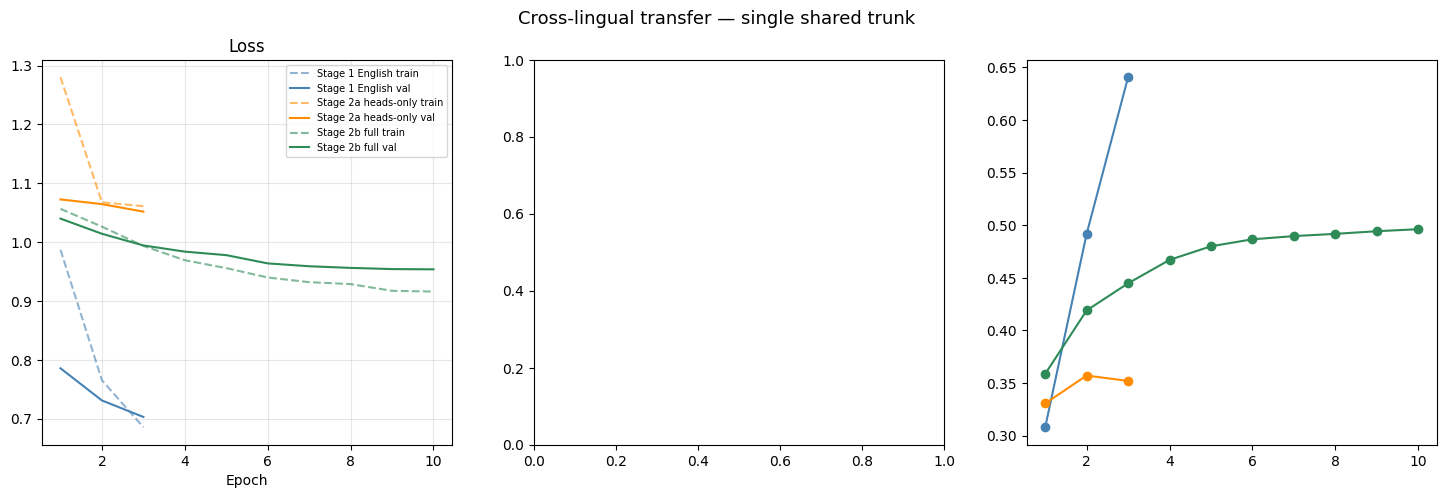

In [18]:
# ── Cell 15: Training curves ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Cross-lingual transfer — single shared trunk", fontsize=13)

for h, lbl, col in [
    (history_s1,  "Stage 1 English",       "steelblue"),
    (history_s2a, "Stage 2a heads-only",   "darkorange"),
    (history_s2b, "Stage 2b full",         "seagreen"),
]:
    ep  = [x["epoch"] for x in h]
    tl  = [x["train_loss"] for x in h]
    vl  = [x["loss"] for x in h]
    jcs_h = [x.get("jcs", 0) for x in h]
    axes[0].plot(ep, tl, "--", color=col, alpha=0.6, label=f"{lbl} train")
    axes[0].plot(ep, vl, "-",  color=col,            label=f"{lbl} val")
    axes[2].plot(ep, jcs_h, "o-", color=col, label=lbl)

axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch")
axes[0].legend(fontsize=7); axes[0].grid(True, alpha=0.3)

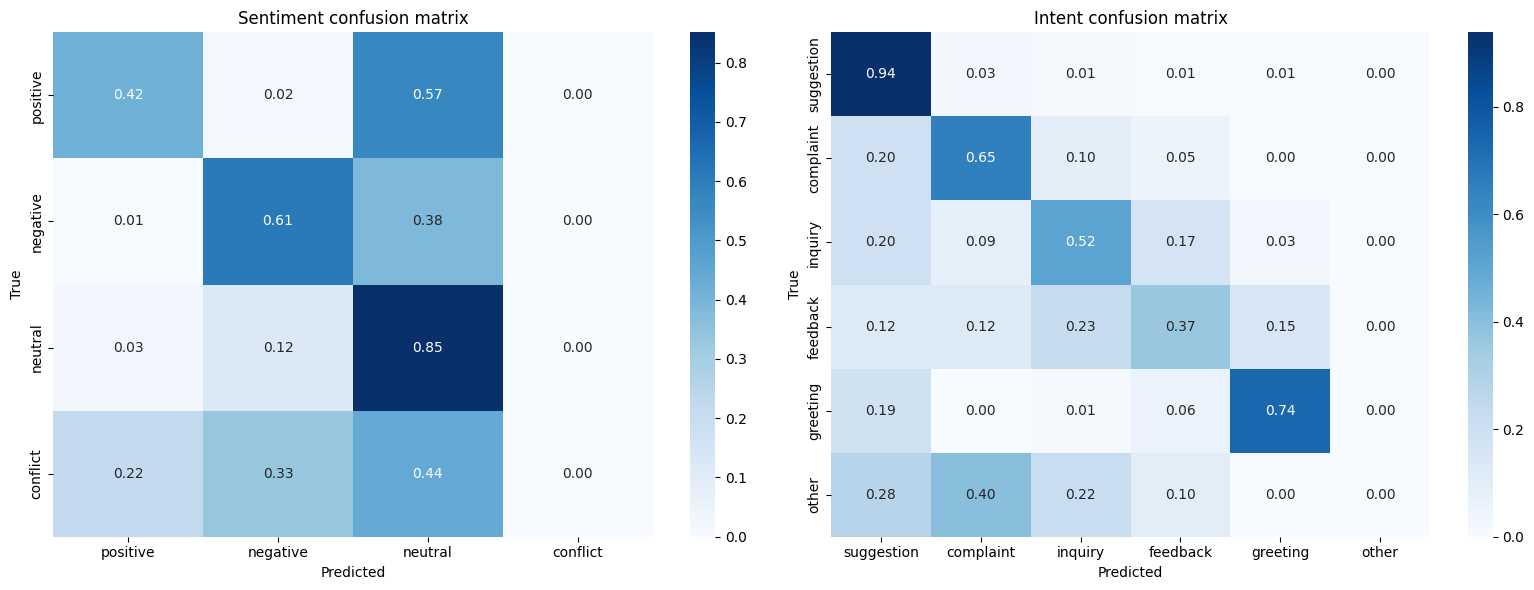

Plots saved.


In [19]:
# Confusion matrices (Stage 2b test set)
for ax, preds, labels, classes, title in [
    (axes[1], all_sp, all_sl, SENTIMENT_CLASSES, "Sentiment"),
    (axes[1], all_ip, all_il, INTENT_CLASSES,    "Intent"),   # overwritten below
]:
    pass

fig2, cm_axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, preds, labels, classes, title in [
    (cm_axes[0], all_sp, all_sl, SENTIMENT_CLASSES, "Sentiment"),
    (cm_axes[1], all_ip, all_il, INTENT_CLASSES,    "Intent"),
]:
    cm = confusion_matrix(labels, preds).astype(float)
    cm /= cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt=".2f",
                xticklabels=classes, yticklabels=classes,
                cmap="Blues", ax=ax)
    ax.set_title(title + " confusion matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

axes[2].set_title("Val JCS by stage"); axes[2].set_xlabel("Epoch")
axes[2].legend(fontsize=8); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"),  dpi=150)
fig2.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices.png"), dpi=150)
plt.show()
print("Plots saved.")

In [20]:
# ── Cell 16: Save final model ─────────────────────────────────────────────────
model.encoder.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
torch.save(model.state_dict(), os.path.join(MODEL_DIR, "joint_single_head.pt"))
print(f"\nModel saved → {MODEL_DIR}")
for f in os.listdir(MODEL_DIR):
    mb = os.path.getsize(os.path.join(MODEL_DIR, f)) / 1e6
    print(f"  {f}  ({mb:.1f} MB)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved → /kaggle/working/saved_model
  config.json  (0.0 MB)
  joint_single_head.pt  (1114.4 MB)
  model.safetensors  (1112.2 MB)
  tokenizer.json  (16.8 MB)
  tokenizer_config.json  (0.0 MB)


In [21]:
# ── Cell 17: Inference (identical to your original) ──────────────────────────
def predict(text):
    model.eval()
    text = clean_text(str(text))
    enc  = tokenizer(text, max_length=MAX_LEN,
                     padding="max_length", truncation=True,
                     return_tensors="pt")
    with torch.no_grad():
        s_log, i_log = model(
            enc["input_ids"].to(DEVICE),
            enc["attention_mask"].to(DEVICE),
        )
    sp = torch.softmax(s_log, -1).cpu().numpy()[0]
    ip = torch.softmax(i_log, -1).cpu().numpy()[0]
    return {
        "text":                 text,
        "sentiment":            SENTIMENT_CLASSES[sp.argmax()],
        "sentiment_confidence": round(float(sp.max()), 4),
        "intent":               INTENT_CLASSES[ip.argmax()],
        "intent_confidence":    round(float(ip.max()), 4),
        "sentiment_probs": {c: round(float(p), 4) for c, p in zip(SENTIMENT_CLASSES, sp)},
        "intent_probs":    {c: round(float(p), 4) for c, p in zip(INTENT_CLASSES,   ip)},
    }

def pretty_print(r):
    print("\n" + "-" * 52)
    print(f"  Text      : {r['text']}")
    print(f"  Sentiment : {r['sentiment']:<12} (conf: {r['sentiment_confidence']:.1%})")
    print(f"  Intent    : {r['intent']:<12} (conf: {r['intent_confidence']:.1%})")
    print("  Sentiment probs:")
    for c, p in r["sentiment_probs"].items():
        print(f"    {c:<12} {p:.4f}")
    print("  Intent probs:")
    for c, p in r["intent_probs"].items():
        print(f"    {c:<12} {p:.4f}")

samples = [
    "meka harima wadiyai mata refund ekk one",
    "oyage service eka best godak stuthi",
    "delivery date eka kawadad",
    "me product eka use karanne kohomad",
]
for text in samples:
    pretty_print(predict(text))


----------------------------------------------------
  Text      : meka harima wadiyai mata refund ekk one
  Sentiment : neutral      (conf: 66.8%)
  Intent    : suggestion   (conf: 91.3%)
  Sentiment probs:
    positive     0.0397
    negative     0.2528
    neutral      0.6680
    conflict     0.0395
  Intent probs:
    suggestion   0.9129
    complaint    0.0196
    inquiry      0.0188
    feedback     0.0207
    greeting     0.0120
    other        0.0161

----------------------------------------------------
  Text      : oyage service eka best godak stuthi
  Sentiment : neutral      (conf: 82.8%)
  Intent    : suggestion   (conf: 92.8%)
  Sentiment probs:
    positive     0.0326
    negative     0.1088
    neutral      0.8284
    conflict     0.0302
  Intent probs:
    suggestion   0.9280
    complaint    0.0093
    inquiry      0.0160
    feedback     0.0155
    greeting     0.0150
    other        0.0162

----------------------------------------------------
  Text      : delive

In [23]:
inference_data = [
    "හෙලෝ 😊 කොහොමද?",
    "මට order එකක් දාන්න පුළුවන්ද?",
    "මේ app එක හොඳයි 👍",
    "service එක ඉතාම නරකයි 😡",
    "ඔයාගේ help එකට thanks 🙏",
    "මේ feature එක add කරන්න පුළුවන්ද? 🤔",
    "ඇයි මේක load වෙන්නේ නැත්තේ? 😕",
    "සුභ උදෑසනක් 🌅",
    "delivery එක late 😤",
    "මේක average වගේ 😐",

    "මට bill එක check කරන්න ඕනේ 🧾",
    "ඔබට ස්තූතියි ❤️",
    "system එක crash වෙනවා 😡",
    "මේක improve කරන්න පුළුවන් 💡",
    "hi 👋",
    "මට password reset කරගන්න ඕනේ 🔑",
    "response එක slow 😒",
    "great service 👍🔥",
    "මේක හරිද කියලා දන්නේ නැහැ 🤷",
    "hello 😊",

    "app එක awesome 😍",
    "මේක bug එකක් වගේ 🐞",
    "please help කරන්න 🙏",
    "service එක okay 😐",
    "delivery delay වෙලා 😠",
    "nice work 👏",
    "error එක fix කරන්න 😤",
    "suggest එකක් තියෙනවා 💡",
    "good morning ☀️",
    "මට info එකක් ඕනේ 📄",

    "thank you so much ❤️",
    "login වෙන්න බැහැ 😡",
    "app එක improve වෙලා 👍",
    "මේක confusing 😕",
    "hi there 😄",
    "reset link එක නැහැ 😤",
    "feedback එකක් දෙන්නම් ✍️",
    "bad experience 😠",
    "neutral feel එකක් 😐",
    "help needed 🙏",

    "super app 😍🔥",
    "issue එක solve කරන්න 🛠️",
    "suggestion එකක් තියෙනවා 💡",
    "hello hello 😄",
    "response slow 😒",
    "good job 👍",
    "error message එක එනවා 😡",
    "info provide කරන්න 📄",
    "okay experience 😐",
    "hi 😊",

    "excellent service 🌟",
    "app crash වෙනවා 😤",
    "add new feature 💡",
    "hello guys 👋",
    "slow performance 😒",
    "thanks a lot 🙏",
    "bug fix කරන්න 🐞",
    "average system 😐",
    "inquiry එකක් තියෙනවා 🤔",
    "good evening 🌙",

    "really helpful ❤️",
    "terrible service 😡",
    "improve UI 💡",
    "hi hi 😄",
    "delay issue 😠",
    "nice experience 👍",
    "problem එක solve කරන්න 😤",
    "neutral response 😐",
    "need details 📄",
    "hello 😊",

    "awesome work 🔥",
    "not working 😡",
    "suggestion add කරන්න 💡",
    "hi team 👋",
    "slow loading 😒",
    "thanks 🙏",
    "error fix කරන්න 🛠️",
    "okay system 😐",
    "more info needed 🤔",
    "hello there 😊",

    "great job 👍",
    "bad support 😠",
    "new feature please 💡",
    "hi 😊",
    "delay again 😤",
    "nice app ❤️",
    "issue unresolved 😡",
    "average experience 😐",
    "details please 📄",
    "hello 👋",

    "super service 🌟",
    "app not responding 😡",
    "improve speed 💡",
    "hi everyone 😊",
    "slow app 😒",
    "thank you 🙏",
    "bug issue 🐞",
    "neutral feedback 😐",
    "need help 🤔",
    "hello 😊"
]

In [24]:
for text in inference_data:
    pretty_print(predict(text))


----------------------------------------------------
  Text      : හෙලෝ 😊 කොහොමද?
  Sentiment : neutral      (conf: 89.4%)
  Intent    : suggestion   (conf: 73.6%)
  Sentiment probs:
    positive     0.0439
    negative     0.0398
    neutral      0.8939
    conflict     0.0224
  Intent probs:
    suggestion   0.7363
    complaint    0.0179
    inquiry      0.0521
    feedback     0.0533
    greeting     0.1018
    other        0.0385

----------------------------------------------------
  Text      : මට order එකක් දාන්න පුළුවන්ද?
  Sentiment : neutral      (conf: 88.1%)
  Intent    : suggestion   (conf: 91.8%)
  Sentiment probs:
    positive     0.0275
    negative     0.0631
    neutral      0.8806
    conflict     0.0288
  Intent probs:
    suggestion   0.9183
    complaint    0.0099
    inquiry      0.0164
    feedback     0.0170
    greeting     0.0182
    other        0.0203

----------------------------------------------------
  Text      : මේ app එක හොඳයි 👍
  Sentiment : posit